# AI-Based Customer Spending Prediction
**Veda Technology – AI & ML Internship Project**

## Objective
Build a beginner-friendly machine learning system that predicts whether a customer belongs to the **Low, Medium, or High** spending category using demographic and purchasing-related information.

## Tools and Libraries
Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn and Jupyter Notebook.

## Project workflow
1. Load and understand the customer dataset.
2. Clean data and perform exploratory data analysis.
3. Prepare features and target labels.
4. Train Logistic Regression and Random Forest classifiers.
5. Compare model performance using Accuracy, Precision, Recall and F1-score.
6. Review the confusion matrix and feature importance.
7. Predict the spending category of a new customer.

> This project uses a reproducible sample dataset created for learning and demonstration. It is not real customer or financial data.

## 1. Import required libraries

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

RANDOM_STATE = 42
print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Load the dataset

In [2]:
# Google Colab-ல run பண்ணா CSV இல்லன்னா upload கேட்கும்; Jupyter-ல same folder-ல இருந்தா நேரா load ஆகும்.
import os
if not os.path.exists("customer_spending_dataset.csv"):
    try:
        from google.colab import files
        print("Please upload customer_spending_dataset.csv")
        files.upload()
    except ImportError:
        raise FileNotFoundError("customer_spending_dataset.csv should be in the same folder as this notebook.")

df = pd.read_csv("customer_spending_dataset.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Shape: (1200, 13)


,customer_id,age,gender,annual_income,purchase_frequency,avg_order_value,total_orders,recency_days,discount_usage,category_diversity,online_orders_ratio,membership,spending_category
0,CUST0001,22,Female,114888,8,130.25,11,115,0.39,4,0.36,Silver,High
1,CUST0002,59,Male,42324,6,123.27,4,74,0.94,2,0.11,Silver,Medium
2,CUST0003,52,Male,66549,13,79.87,15,167,0.70,7,0.34,Silver,Medium
3,CUST0004,41,Male,39124,10,166.44,7,128,0.97,4,0.82,Gold,High
4,CUST0005,40,Male,47893,9,100.08,12,14,0.85,3,0.68,Basic,Medium


## 3. Understand and clean the data

In [3]:
print("Dataset information:")
df.info()

print("\nMissing values:")
display(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

# Remove duplicate rows, if any
df = df.drop_duplicates()

# Remove rows without a target label
df = df.dropna(subset=["spending_category"])

print("\nDataset shape after cleaning:", df.shape)
print("\nSpending category counts:")
display(df["spending_category"].value_counts())

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   customer_id          1200 non-null   str    
 1   age                  1200 non-null   int64  
 2   gender               1200 non-null   str    
 3   annual_income        1200 non-null   int64  
 4   purchase_frequency   1200 non-null   int64  
 5   avg_order_value      1200 non-null   float64
 6   total_orders         1200 non-null   int64  
 7   recency_days         1200 non-null   int64  
 8   discount_usage       1200 non-null   float64
 9   category_diversity   1200 non-null   int64  
 10  online_orders_ratio  1200 non-null   float64
 11  membership           1200 non-null   str    
 12  spending_category    1200 non-null   str    
dtypes: float64(3), int64(6), str(4)
memory usage: 122.0 KB

Missing values:

Duplicate rows: 0

Dataset shape after cleaning: (1200,

,0
customer_id,0
age,0
gender,0
annual_income,0
purchase_frequency,0
avg_order_value,0
total_orders,0
recency_days,0
discount_usage,0
category_diversity,0


,count
spending_category,
Low,408
High,396
Medium,396


## 4. Exploratory Data Analysis (EDA)

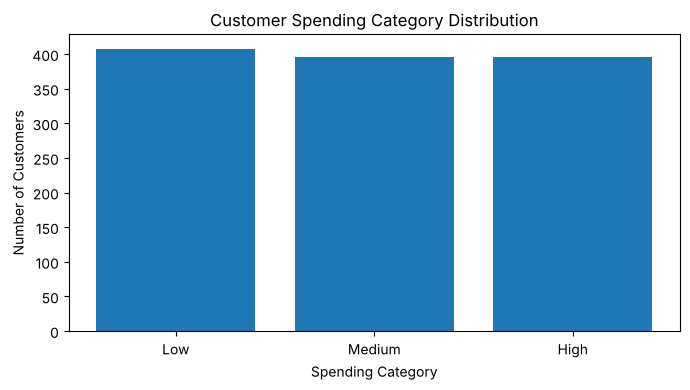

In [4]:
# Visualization 1: Spending category distribution
category_counts = df["spending_category"].value_counts().reindex(["Low", "Medium", "High"])
plt.figure(figsize=(7, 4))
plt.bar(category_counts.index, category_counts.values)
plt.title("Customer Spending Category Distribution")
plt.xlabel("Spending Category")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

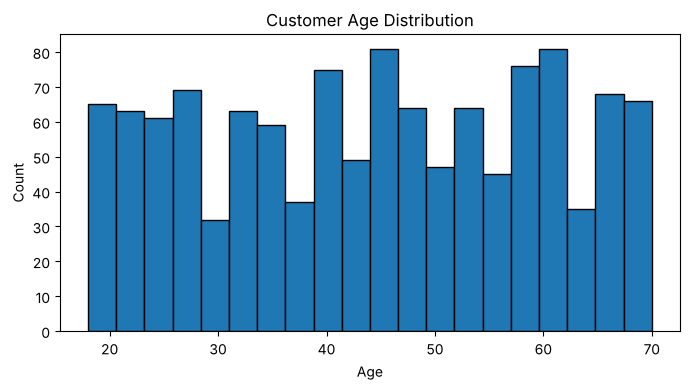

In [5]:
# Visualization 2: Age distribution
plt.figure(figsize=(7, 4))
plt.hist(df["age"], bins=20, edgecolor="black")
plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

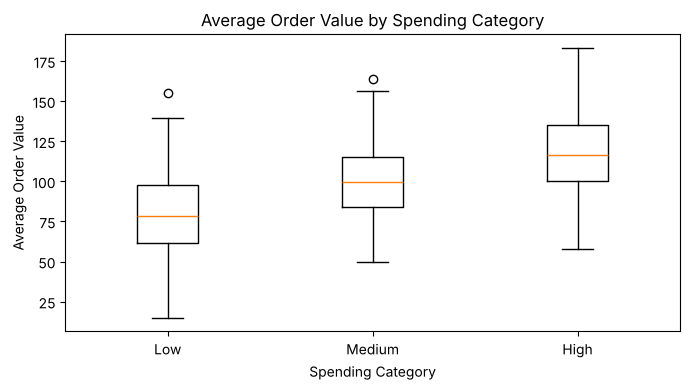

In [6]:
# Visualization 3: Average order value by spending category
box_data = [df.loc[df["spending_category"] == label, "avg_order_value"]
            for label in ["Low", "Medium", "High"]]
plt.figure(figsize=(7, 4))
plt.boxplot(box_data)
plt.xticks([1, 2, 3], ["Low", "Medium", "High"])
plt.title("Average Order Value by Spending Category")
plt.xlabel("Spending Category")
plt.ylabel("Average Order Value")
plt.tight_layout()
plt.show()

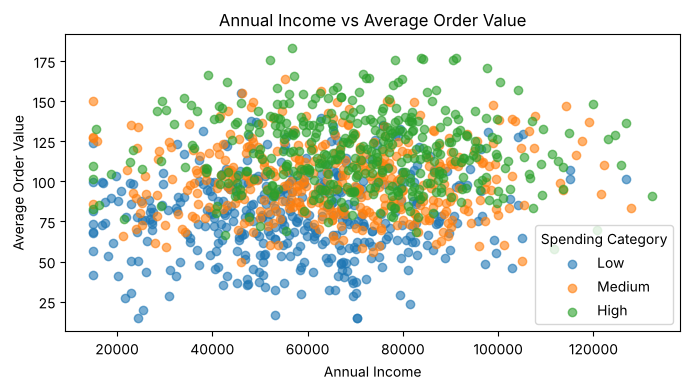

In [7]:
# Visualization 4: Annual income vs average order value
plt.figure(figsize=(7, 4))
for label in ["Low", "Medium", "High"]:
    subset = df[df["spending_category"] == label]
    plt.scatter(subset["annual_income"], subset["avg_order_value"], label=label, alpha=0.6)
plt.title("Annual Income vs Average Order Value")
plt.xlabel("Annual Income")
plt.ylabel("Average Order Value")
plt.legend(title="Spending Category")
plt.tight_layout()
plt.show()

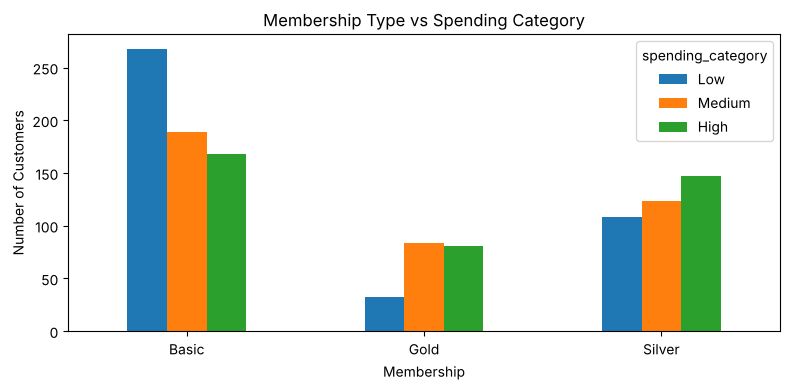

In [8]:
# Visualization 5: Membership type by spending category
membership_counts = pd.crosstab(df["membership"], df["spending_category"])
membership_counts = membership_counts[["Low", "Medium", "High"]]
membership_counts.plot(kind="bar", figsize=(8, 4))
plt.title("Membership Type vs Spending Category")
plt.xlabel("Membership")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 5. Feature engineering and preprocessing

In [9]:
# customer_id is an identifier, not a useful predictive feature.
# The target column is spending_category.
# No spending total used to create the target is included in the predictors.
X = df.drop(columns=["customer_id", "spending_category"])
y = df["spending_category"]

numeric_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object"]).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("Feature preparation completed.")

Numeric features: ['age', 'annual_income', 'purchase_frequency', 'avg_order_value', 'total_orders', 'recency_days', 'discount_usage', 'category_diversity', 'online_orders_ratio']
Categorical features: ['gender', 'membership']
Feature preparation completed.


## 6. Split data into training and testing sets

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 960
Testing rows: 240


## 7. Train two classification models

In [11]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(
        n_estimators=250, max_depth=12, min_samples_split=4,
        random_state=RANDOM_STATE, class_weight="balanced"
    )
}

trained_models = {}
results = []

for model_name, classifier in models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])
    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    trained_models[model_name] = pipeline
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision (weighted)": precision_score(y_test, predictions, average="weighted", zero_division=0),
        "Recall (weighted)": recall_score(y_test, predictions, average="weighted", zero_division=0),
        "F1-score (weighted)": f1_score(y_test, predictions, average="weighted", zero_division=0)
    })

results_df = pd.DataFrame(results).sort_values("F1-score (weighted)", ascending=False)
display(results_df.round(3))

,Model,Accuracy,Precision (weighted),Recall (weighted),F1-score (weighted)
1,Random Forest,0.783,0.787,0.783,0.785
0,Logistic Regression,0.750,0.764,0.750,0.754


## 8. Compare model performance

Best model based on weighted F1-score: Random Forest


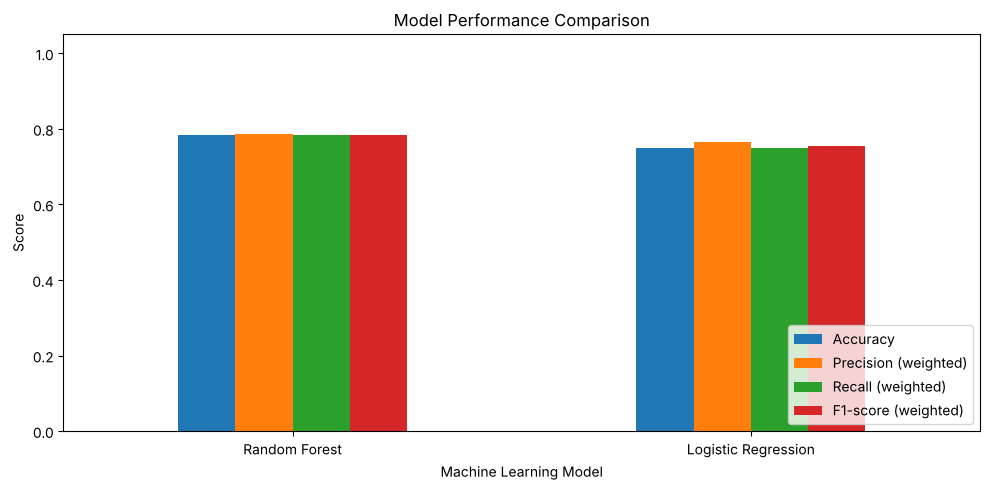

In [12]:
metrics_to_plot = results_df.set_index("Model")
metrics_to_plot.plot(kind="bar", figsize=(10, 5), ylim=(0, 1.05))
plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Machine Learning Model")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]
print("Best model based on weighted F1-score:", best_model_name)

## 9. Confusion matrix and classification report

Classification Report:
              precision    recall  f1-score   support

        High       0.82      0.78      0.80        79
         Low       0.88      0.85      0.86        82
      Medium       0.67      0.71      0.69        79

    accuracy                           0.78       240
   macro avg       0.79      0.78      0.78       240
weighted avg       0.79      0.78      0.78       240



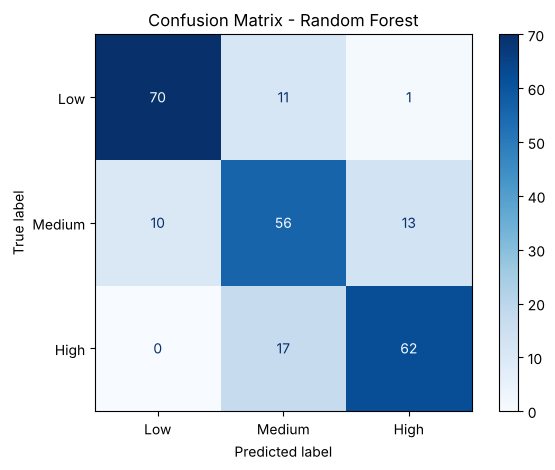

In [13]:
best_predictions = best_model.predict(X_test)
labels = ["Low", "Medium", "High"]

cm = confusion_matrix(y_test, best_predictions, labels=labels)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(cmap="Blues", values_format="d")
plt.title(f"Confusion Matrix - {best_model_name}")
plt.tight_layout()
plt.show()

print("Classification Report:")
print(classification_report(y_test, best_predictions, zero_division=0))

## 10. Feature importance / model interpretation

,Feature,Importance
3,num__avg_order_value,0.257393
2,num__purchase_frequency,0.196283
4,num__total_orders,0.116190
1,num__annual_income,0.097006
5,num__recency_days,0.060924
8,num__online_orders_ratio,0.059207
6,num__discount_usage,0.058499
0,num__age,0.056436
7,num__category_diversity,0.036760
12,cat__membership_Basic,0.018650


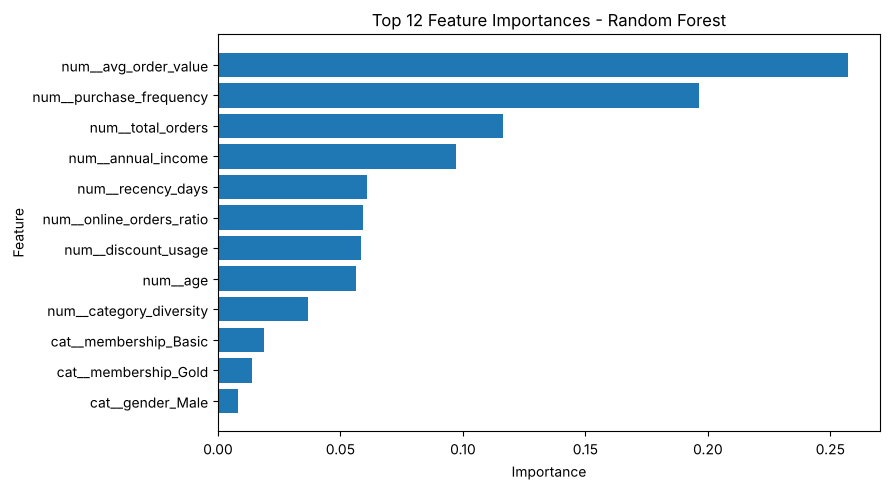

In [14]:
# Random Forest provides feature importance values after preprocessing.
rf_pipeline = trained_models["Random Forest"]
rf_classifier = rf_pipeline.named_steps["classifier"]
feature_names = rf_pipeline.named_steps["preprocessor"].get_feature_names_out()
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_classifier.feature_importances_
}).sort_values("Importance", ascending=False).head(12)

display(importance_df)

plt.figure(figsize=(9, 5))
plt.barh(importance_df["Feature"], importance_df["Importance"])
plt.title("Top 12 Feature Importances - Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## 11. Predict spending category for a new customer

In [15]:
new_customer = pd.DataFrame([{
    "age": 29,
    "gender": "Female",
    "annual_income": 72000,
    "purchase_frequency": 10,
    "avg_order_value": 110.0,
    "total_orders": 12,
    "recency_days": 15,
    "discount_usage": 0.25,
    "category_diversity": 5,
    "online_orders_ratio": 0.70,
    "membership": "Gold"
}])

predicted_category = best_model.predict(new_customer)[0]
print("Predicted customer spending category:", predicted_category)

if hasattr(best_model.named_steps["classifier"], "predict_proba"):
    probabilities = best_model.predict_proba(new_customer)[0]
    probability_table = pd.DataFrame({
        "Spending Category": best_model.classes_,
        "Prediction Probability": probabilities
    }).sort_values("Prediction Probability", ascending=False)
    display(probability_table.round(3))

Predicted customer spending category: High


,Spending Category,Prediction Probability
0,High,0.783
2,Medium,0.175
1,Low,0.042


## 12. Short business insight report

In [16]:
print("BUSINESS INSIGHTS")
print("-----------------")
print("1. Customers are grouped into Low, Medium and High spending categories.")
print("2. Purchase frequency and average order value are useful purchasing signals.")
print("3. Membership type, recency and income can provide additional customer context.")
print("4. The model comparison helps select a suitable classifier using weighted F1-score.")
print("5. A business can use these predictions to plan customer segments and suitable offers.")
print("\nImportant: These are learning insights from a synthetic sample dataset.")

BUSINESS INSIGHTS
-----------------
1. Customers are grouped into Low, Medium and High spending categories.
2. Purchase frequency and average order value are useful purchasing signals.
3. Membership type, recency and income can provide additional customer context.
4. The model comparison helps select a suitable classifier using weighted F1-score.
5. A business can use these predictions to plan customer segments and suitable offers.

Important: These are learning insights from a synthetic sample dataset.


## 13. Conclusion
This project demonstrates an end-to-end machine learning workflow for customer spending category prediction. It includes data cleaning, five visualizations, preprocessing, two classification algorithms, model evaluation, a confusion matrix, feature interpretation and a sample prediction.

## How to run in Google Colab
1. Download the project ZIP and extract it.
2. Open `Customer_Spending_Prediction.ipynb` in Google Colab.
3. Upload `customer_spending_dataset.csv` to the Colab session using the Files panel.
4. Run the notebook cells from top to bottom using **Runtime → Run all**.
5. Review the model metrics, charts and sample prediction.

## Learning outcomes
- Understanding a complete beginner-level ML classification workflow.
- Performing EDA and creating visualizations.
- Handling numerical and categorical data with preprocessing pipelines.
- Training and comparing Logistic Regression and Random Forest.
- Evaluating a classifier using multiple metrics.